# Event-locked kernels, M2: LEC vs PFC

Stage 1, the reset test and Kanter part 1. Loads and plots only. Numbers come from `run_event_kernels.py` and `run_population_drift.py`, one
job per recday through `sbatch_files/submit_event_kernels.sh`, merged with `--merge`. Write-ups:
`code/EVENT_KERNELS.md` (2026-10-12 entry) and `code/POPULATION_DRIFT.md`.

- Design: `kin='strict'`; analysis sessions are ABCD sessions with >= 10 trials (LEC also >= 5 as a
  sensitivity arm); leave one session out; Freedman-Lane, n_perm 100.
- A unit is **locked** to a block when p < 0.05 and its held-out cpd > 0. The exact null rate of
  p < 0.05 at n_perm 100 is 5/101.
- Every summary is per mouse: the recday mean, then the mouse mean (the `anatomy_split` convention).

Figures F1-F14 are written to `data/figures/event_kernels/M2/` and `data/figures/population_drift/M2/`.

In [1]:
RUN_MODE = 'load'   # never computes; rerun the sbatch jobs and merges instead
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import event_kernels_plots as P
%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
fig_path = lambda name: os.path.join(P.FIG_DIR, name)
drift_path = lambda name: os.path.join(P.DRIFT_FIG_DIR, name)
S1 = {'LEC': P.load_latest(os.path.join(P.STAGE1_DIR, 'stage1_lec_kin-strict_mt10_np100')),
      'PFC': P.load_latest(os.path.join(P.STAGE1_DIR, 'stage1_pfc_kin-strict_mt10_np100'))}
DR = {'LEC': P.load_latest(os.path.join(P.DRIFT_DIR, 'drift_lec_mt10')),
      'PFC': P.load_latest(os.path.join(P.DRIFT_DIR, 'drift_pfc_mt10'))}
for name, m in [*(('stage1 ' + d, v) for d, v in S1.items()), *(('drift ' + d, v) for d, v in DR.items())]:
    print(f"{name}: {os.path.basename(m['_path'])}")

stage1 LEC: stage1_lec_kin-strict_mt10_np100.pkl
stage1 PFC: stage1_pfc_kin-strict_mt10_np100.pkl
drift LEC: drift_lec_mt10.pkl
drift PFC: drift_pfc_mt10.pkl


## Run summary

`rank_only_duplicates`: every training fold's rank deficit is explained by all-zero or duplicated columns (the `pre` columns of the event blocks mark the same rows before the first A).

In [2]:
P.table_run_summary(S1)

,dataset,anchor,recdays,skipped,units,sessions,rank_only_duplicates,r2_cv_median_of_recdays,reset_skipped,n_perm,kin,min_trials
0,LEC,entry,25,1,2742,135,True,0.050682,0,100,strict,10
1,LEC,first_A,25,1,2742,135,False,0.051299,0,100,strict,10
2,PFC,entry,25,1,1229,171,True,0.040478,4,100,strict,10
3,PFC,first_A,25,1,1229,171,False,0.037784,0,100,strict,10


## F1. Fraction of units locked per block

A point per mouse, the bar is the mean of mice, the dashed line the exact null rate. The middle column applies El-Gaby's 20% rule to LEC.

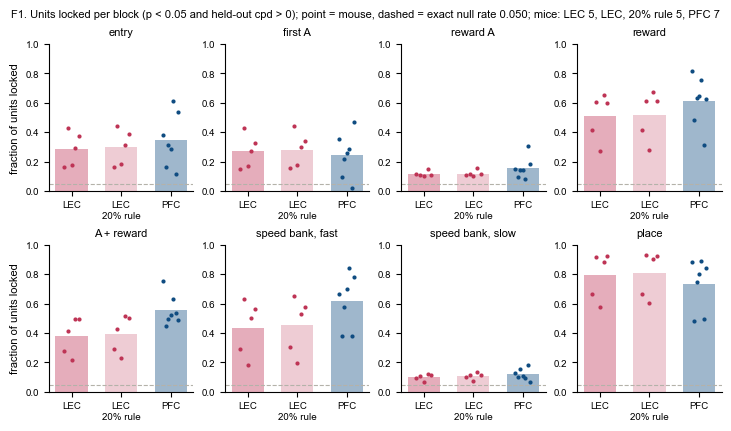

mean    min    max  count
dataset       block                                  
LEC           ev_A         0.117  0.100  0.152      5
              ev_A+reward  0.381  0.217  0.495      5
              ev_entry     0.288  0.167  0.426      5
              ev_first_A   0.271  0.151  0.429      5
              ev_reward    0.508  0.271  0.653      5
              kin_fast     0.434  0.184  0.631      5
              kin_slow     0.102  0.069  0.120      5
              place        0.795  0.579  0.924      5
LEC, 20% rule ev_A         0.119  0.101  0.157      5
              ev_A+reward  0.393  0.228  0.518      5
              ev_entry     0.298  0.167  0.440      5
              ev_first_A   0.282  0.154  0.440      5
              ev_reward    0.519  0.282  0.674      5
              kin_fast     0.452  0.199  0.651      5
              kin_slow     0.107  0.072  0.132      5
              place        0.808  0.607  0.932      5
PFC           ev_A         0.158  0.084  0.304      7
              ev_A+reward  0.554  0.450  0.755      7
              ev_entry     0.344  0.115  0.613      7
              ev_first_A   0.244  0.021  0.472      7
              ev_reward    0.610  0.313  0.815      7
              kin_fast     0.618  0.379  0.844      7
              kin_slow     0.120  0.068  0.185      7
              place        0.735  0.481  0.888      7

In [3]:
P.plot_fraction_locked(S1, out_path=fig_path('F1_fraction_locked')); plt.show()
T1 = P.table_fraction_locked(S1)
T1.groupby(['dataset', 'block'])['fraction'].agg(['mean', 'min', 'max', 'count']).round(3)

In [4]:
T1.pivot_table(index=['dataset', 'mouse'], columns='block', values='fraction').round(3)

block                 ev_A  ev_A+reward  ev_entry  ev_first_A  ev_reward  kin_fast  kin_slow  place
dataset       mouse                                                                                
LEC           ah08   0.113        0.281     0.167       0.151      0.414     0.290     0.097  0.668
              ah10   0.110        0.417     0.426       0.429      0.604     0.631     0.110  0.920
              ly05   0.100        0.217     0.180       0.172      0.271     0.184     0.069  0.579
              ly06   0.152        0.495     0.290       0.275      0.653     0.500     0.120  0.886
              ly07   0.111        0.495     0.378       0.330      0.597     0.566     0.116  0.924
LEC, 20% rule ah08   0.110        0.290     0.167       0.154      0.414     0.302     0.100  0.665
              ah10   0.114        0.426     0.440       0.440      0.615     0.651     0.111  0.932
              ly05   0.101        0.228     0.185       0.178      0.282     0.199     0.072  0.607
              ly06   0.157        0.518     0.312       0.298      0.674     0.530     0.132  0.907
              ly07   0.115        0.505     0.386       0.339      0.610     0.576     0.117  0.927
PFC           ab03   0.148        0.755     0.380       0.354      0.815     0.668     0.130  0.887
              ah03   0.098        0.450     0.160       0.096      0.481     0.383     0.098  0.481
              ah04   0.145        0.497     0.316       0.217      0.633     0.574     0.158  0.745
              ah07   0.147        0.525     0.284       0.260      0.647     0.698     0.108  0.805
              me08   0.084        0.629     0.613       0.287      0.754     0.844     0.096  0.888
              me10   0.304        0.535     0.115       0.021      0.313     0.379     0.185  0.496
              me11   0.181        0.490     0.541       0.472      0.625     0.780     0.068  0.840

## F2. Held-out cpd per block

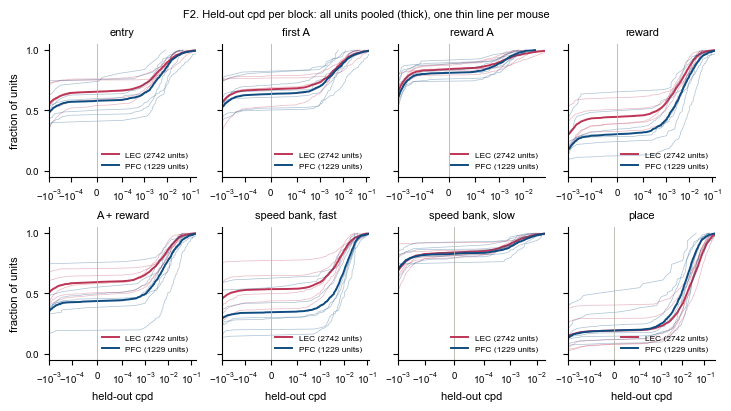

In [5]:
P.plot_cpd_ecdf(S1, out_path=fig_path('F2_cpd_ecdf')); plt.show()

## F3. Event cpd against the fast kinematic bank, for locked units

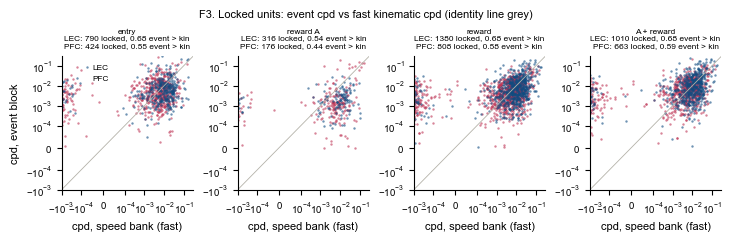

In [6]:
P.plot_event_vs_kin(S1, out_path=fig_path('F3_event_vs_kin')); plt.show()

## F5. Example units

The kernel drawn is partial: the block's effect beyond the other regressors, added to the raw rate at the reference bin.

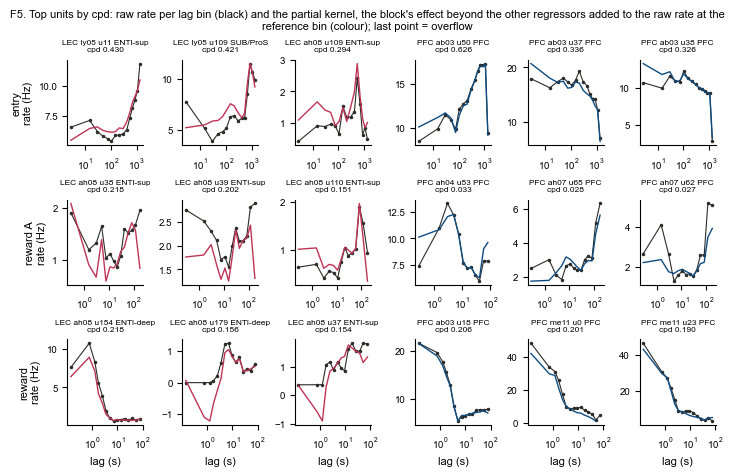

In [7]:
P.plot_example_units(S1, out_path=fig_path('F5_example_units')); plt.show()

## Where the entry kernels peak

Per mouse, of the entry-locked units: the fraction whose largest |beta| sits in the first minute after recording start, or in the overflow bin (> 25 min, mostly the post-task segment). A slow ramp from entry would put it in neither.

In [8]:
P.table_entry_peak_bins(S1).round(3)

,mouse,overflow_f,first_minute_f,dataset
0,ah08,0.0,0.615,LEC
1,ah10,0.0,0.759,LEC
2,ly05,0.0,0.728,LEC
3,ly06,0.0,0.724,LEC
4,ly07,0.0,0.784,LEC
5,ab03,0.0,0.619,PFC
6,ah03,0.0,0.750,PFC
7,ah04,0.0,0.353,PFC
8,ah07,0.0,0.668,PFC
9,me08,0.0,0.180,PFC


## F6. Reset test: entry kernel vs a day-long trend (uncentred, held out)

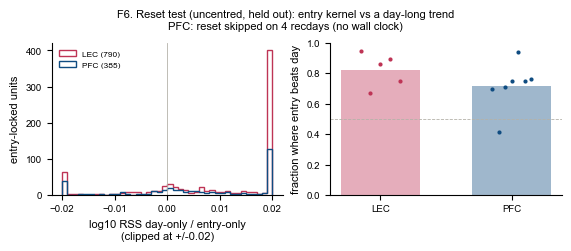

,dataset,units,mouse,fraction_entry_beats_day,n_units
0,LEC,entry-locked,ah08,0.946,134
1,LEC,entry-locked,ah10,0.669,327
2,LEC,entry-locked,ly05,0.864,66
3,LEC,entry-locked,ly06,0.891,103
4,LEC,entry-locked,ly07,0.747,160
5,LEC,all units,ah08,0.833,792
6,LEC,all units,ah10,0.577,772
7,LEC,all units,ly05,0.761,398
8,LEC,all units,ly06,0.856,356
9,LEC,all units,ly07,0.712,424


In [9]:
P.plot_reset(S1, out_path=fig_path('F6_reset')); plt.show()
P.table_reset(S1).round(3)

## F7. Anchor swap: recording start vs the first A, on the same rows

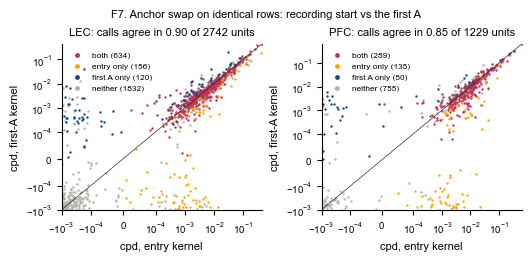

,dataset,mouse,n_units,both,entry_only,first_A_only,agreement
0,LEC,ah08,792,85,49,38,0.890152
1,LEC,ah10,772,302,25,27,0.932642
2,LEC,ly05,398,42,24,22,0.884422
3,LEC,ly06,356,81,22,17,0.890449
4,LEC,ly07,424,124,36,16,0.877358
5,PFC,ab03,197,62,12,7,0.903553
6,PFC,ah03,31,3,2,0,0.935484
7,PFC,ah04,481,86,66,20,0.821206
8,PFC,ah07,249,45,23,19,0.831325
9,PFC,me08,55,15,18,1,0.654545


In [10]:
P.plot_anchor_agreement(S1, out_path=fig_path('F7_anchor_agreement')); plt.show()
P.table_anchor_agreement(S1)

## F9. Reward-kernel latency per mouse

Peak lag of the reward kernel among reward-locked units. Bins are 0.5 s wide up to 2 s, so a sub-bin shift (ah08's speed reference sat 0.55-0.70 s from the other mice's) moves units between bins rather than the median.

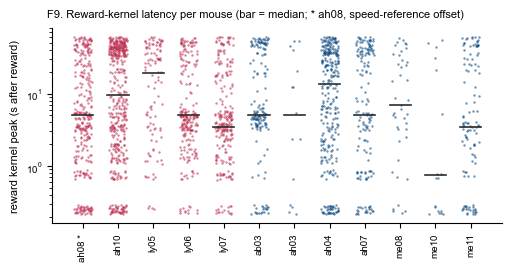

n_units  median_peak_s  first_bin  under_2s
dataset mouse                                             
LEC     ah08       321           5.00      0.143     0.302
        ah10       468           9.50      0.105     0.267
        ly05       107          19.00      0.037     0.196
        ly06       233           5.00      0.052     0.215
        ly07       251           3.50      0.060     0.255
PFC     ab03       161           5.00      0.124     0.174
        ah03        15           5.00      0.267     0.333
        ah04       302          13.50      0.129     0.265
        ah07       157           5.00      0.134     0.306
        me08        42           7.00      0.119     0.214
        me10        18           0.75      0.444     0.667
        me11       113           3.50      0.204     0.345

In [11]:
P.plot_reward_latency(S1, out_path=fig_path('F9_reward_latency')); plt.show()
lat = P.table_reward_latency(S1)
lat.assign(first_bin=lat['peak_s'] < 0.5, under_2s=lat['peak_s'] < 2).groupby(['dataset', 'mouse']).agg(
    n_units=('peak_s', 'size'), median_peak_s=('peak_s', 'median'), first_bin=('first_bin', 'mean'),
    under_2s=('under_2s', 'mean')).round(3)

## F10. LEC regions and PFC

Off-boundary units (>= 50 um from a region transition). The ENTl-deep vs SUB/ProS contrast is rate-matched within recday, computed at mouse level, with labels shuffled within recday (5,000 permutations).

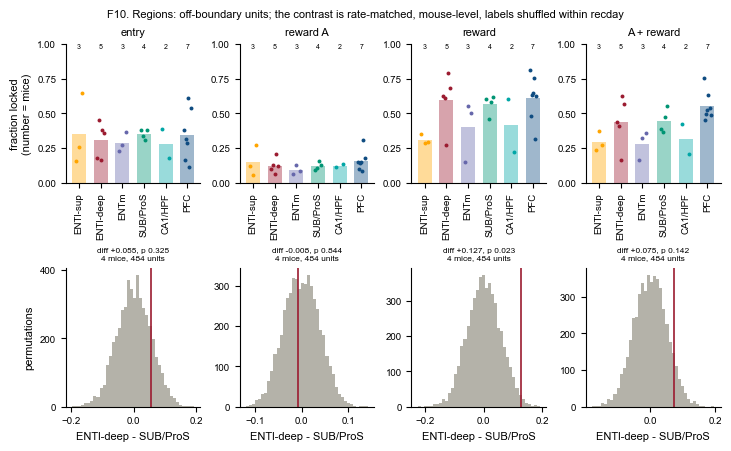

,block,value,observed,p_perm,n_mice,n_units,per_mouse
0,ev_entry,fraction locked,0.0548,0.3251,4,484,"ah10 +0.128, ly05 +0.100, ly06 +0.050, ly07 -0..."
1,ev_entry,cpd,0.0204,0.0048,4,484,"ah10 +0.004, ly05 +0.074, ly06 +0.003, ly07 +0..."
2,ev_A,fraction locked,-0.0084,0.8440,4,484,"ah10 +0.012, ly05 -0.033, ly06 +0.008, ly07 -0..."
3,ev_A,cpd,0.0003,0.8888,4,484,"ah10 +0.000, ly05 +0.001, ly06 +0.002, ly07 -0..."
4,ev_reward,fraction locked,0.1275,0.0234,4,484,"ah10 +0.044, ly05 -0.037, ly06 +0.285, ly07 +0..."
5,ev_reward,cpd,0.0027,0.2855,4,484,"ah10 +0.001, ly05 -0.002, ly06 +0.002, ly07 +0..."
6,ev_A+reward,fraction locked,0.0750,0.1416,4,484,"ah10 +0.050, ly05 -0.033, ly06 +0.132, ly07 +0..."
7,ev_A+reward,cpd,0.0034,0.2334,4,484,"ah10 +0.002, ly05 -0.000, ly06 +0.004, ly07 +0..."


In [12]:
P.plot_regions(S1['LEC'], S1['PFC'], n_perm=5000, out_path=fig_path('F10_regions')); plt.show()
P.table_region_contrasts(S1['LEC'], n_perm=5000).round(4)

In [13]:
P.table_regions(S1['LEC'], S1['PFC']).pivot_table(index=['block', 'group'], values=['fraction', 'cpd_mean'], aggfunc=['mean', 'count']).round(3)

mean             count         
                      cpd_mean fraction cpd_mean fraction
block       group                                        
ev_A        CA1/HPF     -0.004    0.123        2        2
            ENTl-deep   -0.005    0.122        5        5
            ENTl-sup    -0.005    0.147        3        3
            ENTm        -0.007    0.093        3        3
            PFC         -0.003    0.158        7        7
            SUB/ProS    -0.006    0.119        4        4
ev_A+reward CA1/HPF     -0.004    0.316        2        2
            ENTl-deep   -0.000    0.441        5        5
            ENTl-sup    -0.006    0.293        3        3
            ENTm        -0.007    0.282        3        3
            PFC          0.008    0.554        7        7
            SUB/ProS    -0.001    0.446        4        4
ev_entry    CA1/HPF     -0.007    0.280        2        2
            ENTl-deep   -0.009    0.306        5        5
            ENTl-sup    -0.018    0.351        3        3
            ENTm         0.000    0.289        3        3
            PFC          0.000    0.344        7        7
            SUB/ProS    -0.008    0.350        4        4
ev_reward   CA1/HPF      0.001    0.415        2        2
            ENTl-deep    0.004    0.595        5        5
            ENTl-sup    -0.001    0.310        3        3
            ENTm        -0.000    0.400        3        3
            PFC          0.009    0.610        7        7
            SUB/ProS     0.005    0.567        4        4

## F12-F14. Population drift (Kanter part 1)

20-unit draws (20 per recday), so LEC and PFC are compared at the same population size.

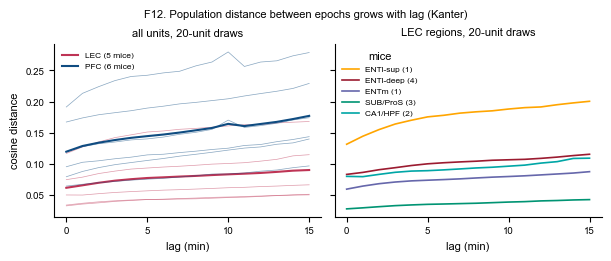

In [14]:
P.plot_distance_vs_lag(DR, out_path=drift_path('F12_distance_vs_lag')); plt.show()

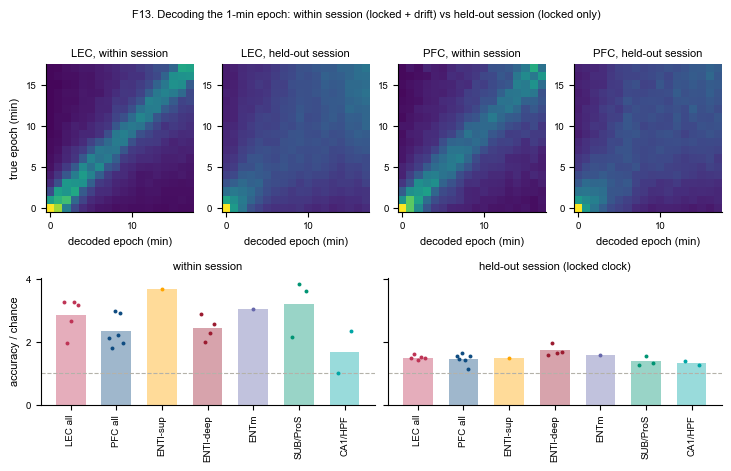

mean                                   min                                   max                                 count                   
measure                     across_over_chance within_over_chance across_over_chance within_over_chance across_over_chance within_over_chance across_over_chance within_over_chance
dataset set       group                                                                                                                                                            
LEC     all 20    all                     1.49               2.87               1.41               1.95               1.59               3.28                  5                  5
        region 20 CA1/HPF                 1.32               1.66               1.26               1.00               1.37               2.33                  2                  2
                  ENTl-deep               1.72               2.43               1.59               1.99               1.97               2.88                  4                  4
                  ENTl-sup                1.50               3.68               1.50               3.68               1.50               3.68                  1                  1
                  ENTm                    1.59               3.04               1.59               3.04               1.59               3.04                  1                  1
                  SUB/ProS                1.38               3.20               1.27               2.15               1.54               3.85                  3                  3
PFC     all 20    all                     1.45               2.33               1.15               1.81               1.63               2.98                  6                  6

In [15]:
P.plot_knn(DR, out_path=drift_path('F13_knn')); plt.show()
K = P.table_knn(DR)
K[K['measure'].isin(['within_over_chance', 'across_over_chance'])].pivot_table(
    index=['dataset', 'set', 'group'], columns='measure', values='value', aggfunc=['mean', 'min', 'max', 'count']).round(2)

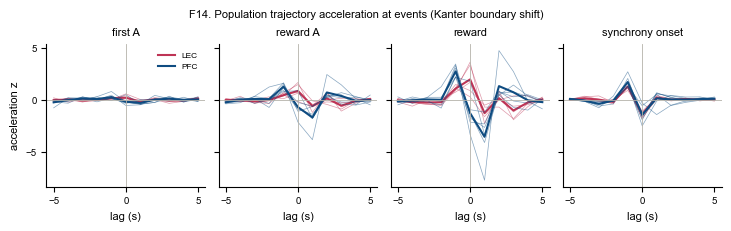

In [16]:
P.plot_event_acceleration(DR, out_path=drift_path('F14_event_acceleration')); plt.show()